# DeltaTrace quickstart

This notebook runs on `dt.datasets.crypt()`, a synthetic **emulation of single-cell-resolution
spatial transcriptomics (ST)**; every cell has an expression profile and a position in the tissue.
It ships with the package, so there is nothing to download, and every cell runs in seconds.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import deltatrace as dt

# colorblind-safe Okabe-Ito colors for the clusters
colors = {"progenitor": "#0072B2", "transit": "#56B4E9", "fate_A": "#009E73",
          "fate_B": "#D55E00", "false_fate": "#CC79A7"}
fates = {k: colors[k] for k in ("fate_A", "fate_B")}

## Investigating the system

The emulated section is crypt-shaped, with progenitors at the base and two walls rising on either
side of a lumen (the crypt lends only its shape; the two fates are built in). Both walls run the
same program, so cells at the same height look alike in expression; only near the top do they
split into `fate_A` (left) and `fate_B` (right). `expr2d` is a 2-D readout of the program genes,
not a UMAP.

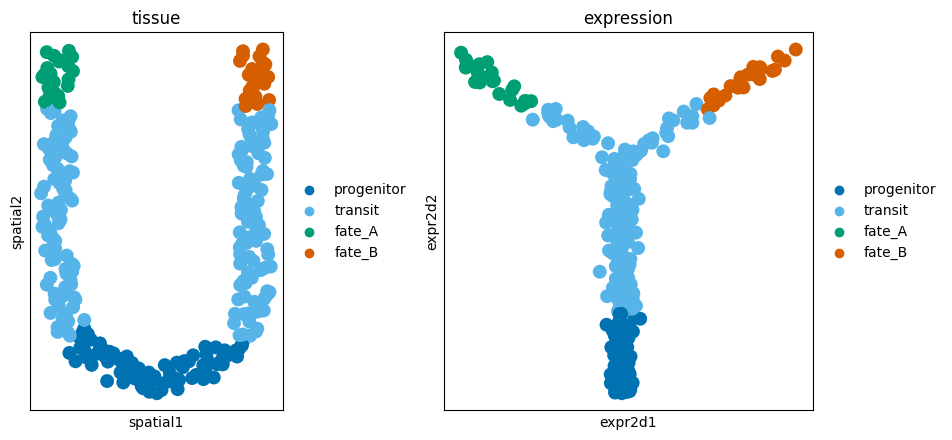

In [2]:
adata, adata_dist = dt.datasets.crypt(n=300)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
sc.pl.embedding(adata, basis="spatial", color="clusters", palette=colors, ax=axs[0],
                show=False, title="tissue")
sc.pl.embedding(adata, basis="expr2d", color="clusters", palette=colors, ax=axs[1],
                show=False, title="expression")
axs[0].set_aspect("equal")
plt.tight_layout()

## Inferring the trajectory

`pp.graphs` builds the integrated graph, which keeps an expression edge only when the two cells
are also close in the tissue. `tl.trajectory` then runs four functions in turn; `tl.endpoints`
samples source and sink cells, `tl.qrot` solves the transport for pseudotime and flow,
`tl.compute_velocity_grid` turns the flow into arrows, and `tl.lineages` assigns fates.

building the 'expr' graph ... finished (0.01 s)


building the 'intr' graph ... finished (0.01 s)


done.


sampling source and sink endpoints ... finished (0.01 s)


solving quadratically-regularized transport ... finished (0.13 s)


building the velocity grid ... finished (0.00 s)


assigning lineages by absorbing chain ... finished (0.00 s)


done.


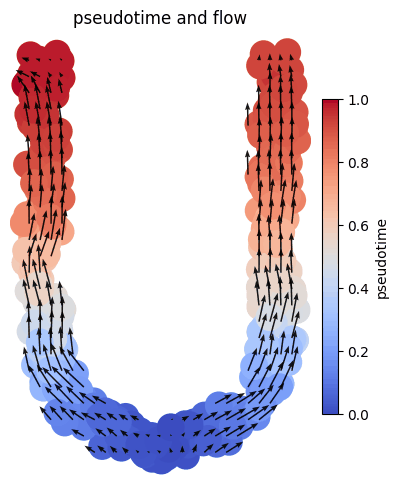

In [3]:
ad = dt.pp.graphs(adata, adata_dist)
dt.tl.trajectory(ad, ["progenitor"], ["fate_A", "fate_B"])
dt.pl.pseudotime(ad, title="pseudotime and flow", colorbar_label="pseudotime")

Color runs from the progenitors (0) to the wall tops (1); arrows show where the flow moves
cells. Fates are in `obs["lineage"]`, with confidence (opacity) in `obs["lineage_confidence"]`.

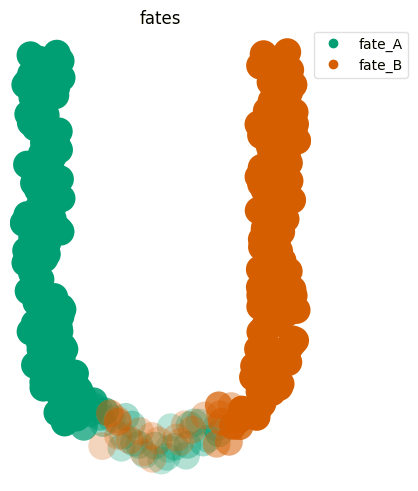

In [4]:
dt.pl.lineages(ad, lineage_colors=fates, title="fates")

### The same, one function at a time

Each step can also be called on its own, for example to look at the sampled endpoints before
solving. With the same arguments the result is identical.

sampling source and sink endpoints ... finished (0.01 s)


done.


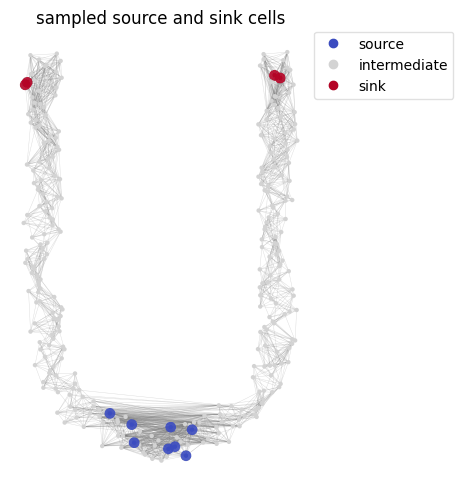

In [5]:
ad_steps = dt.pp.graphs(adata, adata_dist, verbose=0)
gr = dt.tl.endpoints(ad_steps, ad_steps, ["progenitor"], ["fate_A", "fate_B"], graph="intr")
dt.pl.endpoints(gr, ad_steps, title="sampled source and sink cells")

In [6]:
dt.tl.qrot(gr, adata_basis=ad_steps, adata_clust=ad_steps, graph="intr")
dt.tl.compute_velocity_grid(ad_steps, basis="spatial")
dt.tl.lineages(ad_steps, ["progenitor"], ["fate_A", "fate_B"])

print("same pseudotime as tl.trajectory,",
      np.array_equal(ad_steps.obs["pseudotime"], ad.obs["pseudotime"]))

solving quadratically-regularized transport ... finished (0.04 s)


done.


building the velocity grid ... finished (0.00 s)


done.


assigning lineages by absorbing chain ... finished (0.00 s)


done.


same pseudotime as tl.trajectory, True


## Spatial integration vs. expression only

The expression graph alone, built without the tissue distances, links cells at the same height
on opposite walls across the lumen; the integrated graph keeps only edges between cells that are
also close in the tissue.

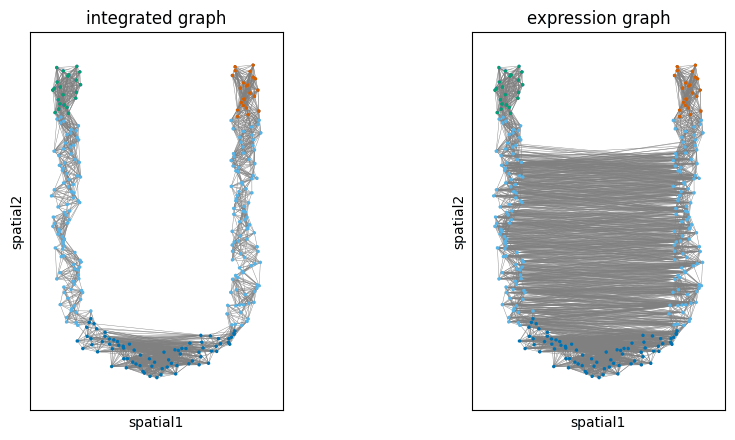

In [7]:
ad_expr = dt.pp.graphs(adata, verbose=0)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, obj, key, title in [(axs[0], ad, "neighbors_intr", "integrated graph"),
                            (axs[1], ad_expr, "neighbors_expr", "expression graph")]:
    sc.pl.embedding(obj, basis="spatial", color="clusters", palette=colors, edges=True, size=25,
                    neighbors_key=key, edges_width=0.3, legend_loc=None, ax=ax, show=False,
                    title=title)
    ax.set_aspect("equal")
plt.tight_layout()

On the expression graph the flow can jump the lumen, so fates mix across the walls.

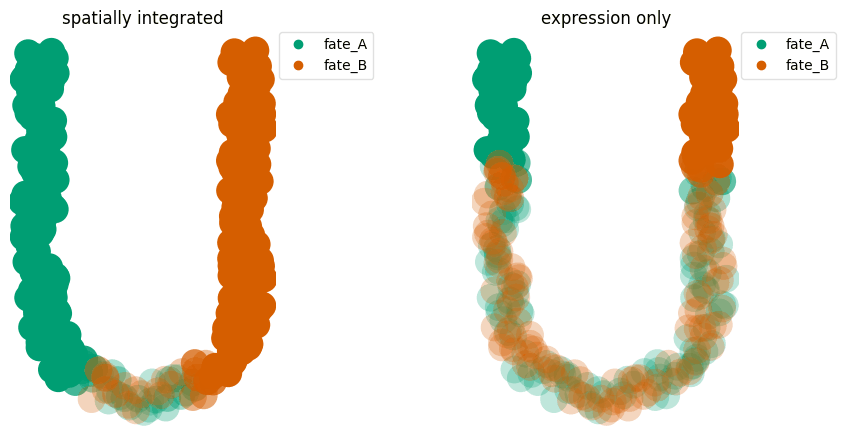

In [8]:
dt.tl.trajectory(ad_expr, ["progenitor"], ["fate_A", "fate_B"], verbose=0)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
dt.pl.lineages(ad, lineage_colors=fates, ax=axs[0], show=False, title="spatially integrated")
dt.pl.lineages(ad_expr, lineage_colors=fates, ax=axs[1], show=False, title="expression only")
plt.tight_layout()

Each wall leads to its own fate, so we can count how many transit cells get there.

In [9]:
x = adata.obsm["spatial"][:, 0]
own_top = np.where(x < np.median(x), "fate_A", "fate_B")
transit = (adata.obs["clusters"] == "transit").to_numpy()
for name, obj in [("spatially integrated", ad), ("expression only", ad_expr)]:
    hit = (obj.obs["lineage"].astype(str).to_numpy() == own_top)[transit].mean()
    conf = np.median(obj.obs["lineage_confidence"].to_numpy()[transit])
    print(f"{name}, {hit:.0%} of transit cells reach their own wall's top "
          f"(median confidence {conf:.2f})")

spatially integrated, 100% of transit cells reach their own wall's top (median confidence 1.00)
expression only, 59% of transit cells reach their own wall's top (median confidence 0.51)


## Discovering fates without sinks

`sink_clusters=None` runs source-only and ranks clusters by `Term = 1 - out / inf` (the flow out of
and into each cluster); the fates sit above the largest gap, which the warning names. `false_fate`
adds a patch of cells that nothing develops into but that looks like an end state, the kind of
population source-only discovery is sensitive to.

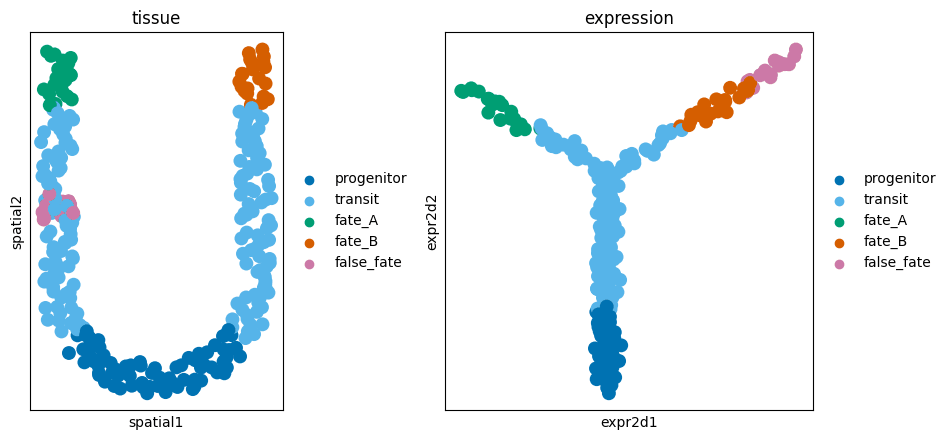

In [10]:
adata2, adata_dist2 = dt.datasets.crypt(n=300, false_fate=0.05)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
sc.pl.embedding(adata2, basis="spatial", color="clusters", palette=colors, ax=axs[0],
                show=False, title="tissue")
sc.pl.embedding(adata2, basis="expr2d", color="clusters", palette=colors, ax=axs[1],
                show=False, title="expression")
axs[0].set_aspect("equal")
plt.tight_layout()

In expression the patch sits just past the tip of `fate_B`, so it looks like that fate's
end; in the tissue it is on the other wall, half-way up.

/tmp/ipykernel_1803947/1778978910.py:3: UserWarning: Source-only run: pseudotime and flow are computed, but no lineages were assigned, because no terminal fates were chosen. The terminality ranking (result['terminality']) suggests ['fate_B', 'fate_A'] (a clear gap). Run again with the fates you choose as sink_clusters=[...] (recommended: sinks give the better trajectory), or assign lineages on this flow with dt.tl.lineages(adata, source_clusters, n_lineages=k).
  res = dt.tl.trajectory(ad2, ["progenitor"], None, verbose=0)
/tmp/ipykernel_1803947/1778978910.py:4: UserWarning: Source-only run: pseudotime and flow are computed, but no lineages were assigned, because no terminal fates were chosen. The terminality ranking (result['terminality']) suggests ['fate_A', 'false_fate'] (no clear gap). Run again with the fates you choose as sink_clusters=[...] (recommended: sinks give the better trajectory), or assign lineages on this flow with dt.tl.lineages(adata, source_clusters, n_lineages=k).


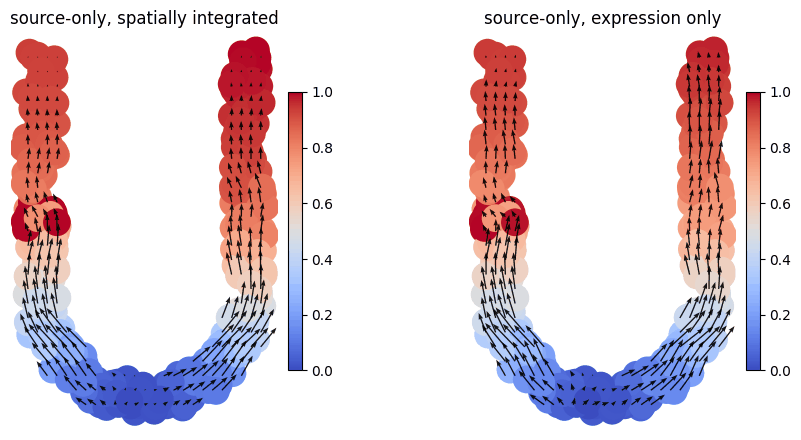

In [11]:
ad2 = dt.pp.graphs(adata2, adata_dist2, verbose=0)
ad2_expr = dt.pp.graphs(adata2, verbose=0)
res = dt.tl.trajectory(ad2, ["progenitor"], None, verbose=0)
res_expr = dt.tl.trajectory(ad2_expr, ["progenitor"], None, verbose=0)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
dt.pl.pseudotime(ad2, ax=axs[0], show=False, title="source-only, spatially integrated")
dt.pl.pseudotime(ad2_expr, ax=axs[1], show=False, title="source-only, expression only")
plt.tight_layout()

On the left the patch is cut off from the flow; its color is only borrowed from its nearest
cells in expression. On the right the flow really runs into it.

In [12]:
res["terminality"]

,inf,out,W,Term
fate_B,0.098592,0.000000,0.098592,1.000000
fate_A,0.098591,0.000000,0.098591,1.000000
transit,1.012229,0.209412,0.802817,0.793118


With the tissue, the patch has no edge into the flow (the cells it resembles sit across the
lumen), so it is not even ranked. Expression only ranks it as an end state instead.

In [13]:
res_expr["terminality"]

,inf,out,W,Term
fate_A,0.092105,0.000000,0.092105,1.000000
false_fate,0.065868,0.000079,0.065789,0.998805
transit,1.002079,0.252079,0.750000,0.748444
fate_B,0.157973,0.065868,0.092104,0.583041


There `fate_B` falls below `transit`; part of the flow reaching `fate_B` runs on into the patch,
so the suggested fates miss `fate_B`.

Once the fates are found, pass them as sinks. No lineage leads to the patch, so its cells stay
unassigned (gray).

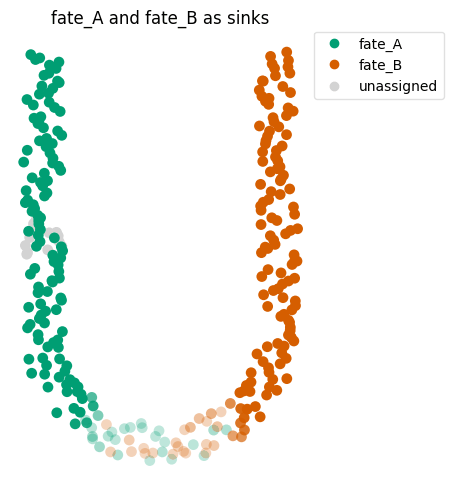

In [14]:
dt.tl.trajectory(ad2, ["progenitor"], ["fate_A", "fate_B"], verbose=0)
dt.pl.lineages(ad2, lineage_colors=fates, node_size=60, title="fate_A and fate_B as sinks")

## Expression only, without spatial data

With no spatial data at all (dissociated scRNA-seq without a paired section), `pp.graphs` needs no
distance matrix and builds the expression graph alone; the flow is then drawn on a UMAP.

building the 'expr' graph from expression alone ... finished (0.00 s)


done.


sampling source and sink endpoints ... finished (0.01 s)


solving quadratically-regularized transport ... finished (0.05 s)


building the velocity grid ... finished (0.00 s)


assigning lineages by absorbing chain ... finished (0.00 s)


done.


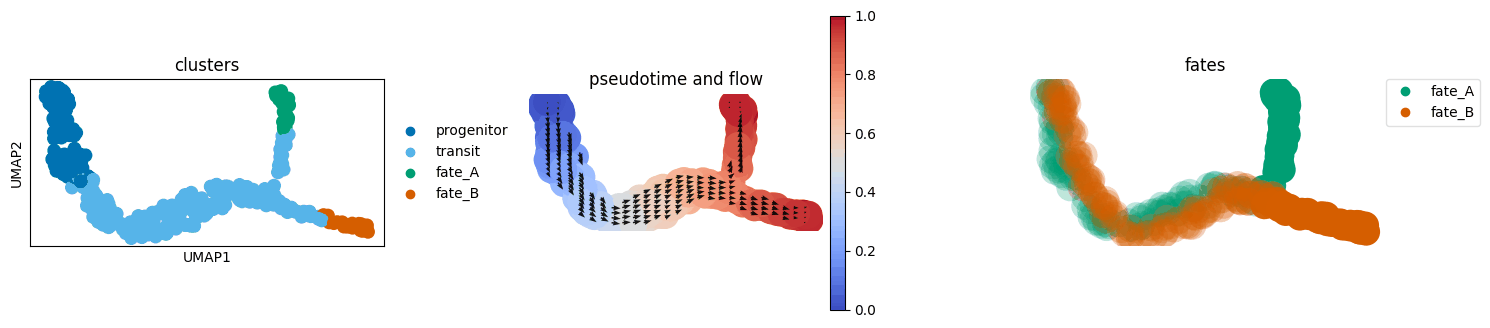

In [15]:
sc_only = adata.copy()
del sc_only.obsm["spatial"]            # no tissue coordinates
sc.tl.umap(sc_only)

ad_sc = dt.pp.graphs(sc_only)          # no distance matrix
dt.tl.trajectory(ad_sc, ["progenitor"], ["fate_A", "fate_B"])

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
sc.pl.umap(ad_sc, color="clusters", palette=colors, ax=axs[0], show=False, title="clusters")
dt.pl.pseudotime(ad_sc, ax=axs[1], show=False, title="pseudotime and flow")
dt.pl.lineages(ad_sc, lineage_colors=fates, ax=axs[2], show=False, title="fates")
axs[0].set_aspect("equal")
plt.tight_layout()

Without the tissue, cells before the fork stay undecided (faint, mixed); only past the fork does
each cell get a clear fate.

## Next

- [`spatial_transcriptomics.ipynb`](spatial_transcriptomics.ipynb) for real single-cell-resolution
  spatial transcriptomics
- [`single_cell_rna_seq.ipynb`](single_cell_rna_seq.ipynb) for dissociated scRNA-seq with a
  paired spatial section